Processed training sources: 500/4243
Processed training sources: 1000/4243
Processed training sources: 1500/4243
Processed training sources: 2000/4243
Processed training sources: 2500/4243
Processed training sources: 3000/4243
Processed training sources: 3500/4243
Processed training sources: 4000/4243
Processed training sources: 4243/4243


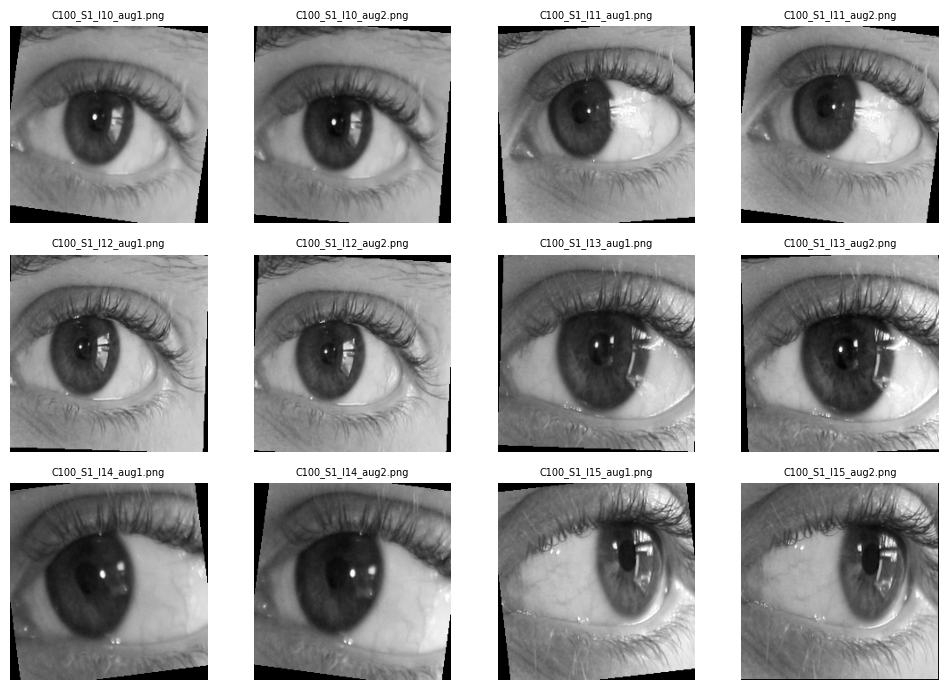


AUGMENTATION SUMMARY
{
  "dataset": "UBIRIS V2",
  "original_training_images": 4243,
  "augmentations_per_source": 2,
  "augmented_images_created": 8486,
  "failed_source_images": 0,
  "validation_images_augmented": false,
  "test_images_augmented": false,
  "augmentation_methods": [
    "rotation up to +/-8 degrees",
    "translation up to +/-3 percent",
    "brightness multiplier 0.90-1.10",
    "contrast multiplier 0.90-1.10"
  ],
  "seed": 42,
  "processing_seconds": 99.15,
  "note": "Filename-derived labels are provisional and have not been independently identity-verified."
}

OUTPUT FILES
OK | UBIRIS_V2_traditional_augmentation_errors.csv | 15 bytes
OK | UBIRIS_V2_traditional_augmentation_preview.png | 621,598 bytes
OK | UBIRIS_V2_traditional_augmentation_summary.json | 566 bytes
OK | UBIRIS_V2_traditional_augmented_metadata.csv | 1,440,142 bytes


In [8]:

from pathlib import Path
from PIL import Image, ImageEnhance
import pandas as pd
import numpy as np
import json, random, time, zipfile

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT = Path("/kaggle/working/ubiris_v2_project")
PRE_DIR = PROJECT / "notebook02_preprocessing"
BASELINE_DIR = PROJECT / "notebook04_baseline_recognition"
OUT_DIR = PROJECT / "notebook05_traditional_augmentation"
IMG_DIR = PRE_DIR / "images_224"
AUG_DIR = OUT_DIR / "augmented_train_images"
AUG_DIR.mkdir(parents=True, exist_ok=True)

train_csv = BASELINE_DIR / "UBIRIS_V2_train_split.csv"
assert train_csv.is_file(), f"Missing training split: {train_csv}"
assert IMG_DIR.is_dir(), f"Missing preprocessed images: {IMG_DIR}"

train_df = pd.read_csv(train_csv)
assert len(train_df) > 0, "Training split is empty"

AUGMENTATIONS_PER_IMAGE = 2
ANGLE_RANGE = 8
SHIFT_FRACTION = 0.03
start = time.time()
records, errors = [], []

for i, row in train_df.reset_index(drop=True).iterrows():
    src = IMG_DIR / (Path(str(row["filename"])).stem + ".png")
    if not src.is_file():
        errors.append({"filename": str(row["filename"]), "error": "Preprocessed image missing"})
        continue

    try:
        with Image.open(src) as im:
            original = im.convert("L")

        for aug_idx in range(AUGMENTATIONS_PER_IMAGE):
            rng = random.Random(SEED + i * 100 + aug_idx)
            angle = rng.uniform(-ANGLE_RANGE, ANGLE_RANGE)
            tx = int(rng.uniform(-SHIFT_FRACTION, SHIFT_FRACTION) * original.width)
            ty = int(rng.uniform(-SHIFT_FRACTION, SHIFT_FRACTION) * original.height)

            aug = original.rotate(
                angle, resample=Image.Resampling.BILINEAR,
                translate=(tx, ty), fillcolor=0
            )
            aug = ImageEnhance.Brightness(aug).enhance(rng.uniform(0.90, 1.10))
            aug = ImageEnhance.Contrast(aug).enhance(rng.uniform(0.90, 1.10))

            out_name = f"{src.stem}_aug{aug_idx + 1}.png"
            out_path = AUG_DIR / out_name
            aug.save(out_path, optimize=True)

            records.append({
                "source_filename": str(row["filename"]),
                "augmented_filename": out_name,
                "augmented_path": str(out_path),
                "subject": str(row["subject"]),
                "label": int(row["label"]),
                "augmentation_index": aug_idx + 1,
                "rotation_degrees": round(angle, 3),
                "translation_x": tx,
                "translation_y": ty
            })
    except Exception as e:
        errors.append({"filename": str(row["filename"]), "error": repr(e)})

    if (i + 1) % 500 == 0 or i + 1 == len(train_df):
        print(f"Processed training sources: {i + 1}/{len(train_df)}")

aug_df = pd.DataFrame(records)
err_df = pd.DataFrame(errors, columns=["filename", "error"])
meta_path = OUT_DIR / "UBIRIS_V2_traditional_augmented_metadata.csv"
err_path = OUT_DIR / "UBIRIS_V2_traditional_augmentation_errors.csv"
summary_path = OUT_DIR / "UBIRIS_V2_traditional_augmentation_summary.json"

aug_df.to_csv(meta_path, index=False)
err_df.to_csv(err_path, index=False)

summary = {
    "dataset": "UBIRIS V2",
    "original_training_images": int(len(train_df)),
    "augmentations_per_source": AUGMENTATIONS_PER_IMAGE,
    "augmented_images_created": int(len(aug_df)),
    "failed_source_images": int(len(err_df)),
    "validation_images_augmented": False,
    "test_images_augmented": False,
    "augmentation_methods": [
        "rotation up to +/-8 degrees",
        "translation up to +/-3 percent",
        "brightness multiplier 0.90-1.10",
        "contrast multiplier 0.90-1.10"
    ],
    "seed": SEED,
    "processing_seconds": round(time.time() - start, 2),
    "note": "Filename-derived labels are provisional and have not been independently identity-verified."
}
summary_path.write_text(json.dumps(summary, indent=2))

# Small visual preview
preview_paths = sorted(AUG_DIR.glob("*.png"))[:12]
if preview_paths:
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(3, 4, figsize=(10, 7))
    for ax, p in zip(axes.flat, preview_paths):
        with Image.open(p) as im:
            ax.imshow(im, cmap="gray")
        ax.set_title(p.name, fontsize=7)
        ax.axis("off")
    for ax in axes.flat[len(preview_paths):]:
        ax.axis("off")
    fig.tight_layout()
    fig.savefig(OUT_DIR / "UBIRIS_V2_traditional_augmentation_preview.png", dpi=130)
    plt.show()
    plt.close(fig)

print("\nAUGMENTATION SUMMARY")
print(json.dumps(summary, indent=2))
print("\nOUTPUT FILES")
for p in sorted(OUT_DIR.iterdir()):
    if p.is_file():
        print(f"OK | {p.name} | {p.stat().st_size:,} bytes")


## Conclusion — Traditional Image Augmentation

Traditional augmentation was successfully applied to the UBIRIS V2 training dataset. A total of 4,243 original training images were used to generate two augmented variants per image, producing **8,486 augmented images**. The transformations included random rotation within ±8°, translation within ±3% of image dimensions, brightness adjustment between 0.90 and 1.10, and contrast adjustment between 0.90 and 1.10.

The augmentation process completed in **99.15 seconds**, with zero failed source images. The validation and test datasets were left unchanged to avoid introducing augmented samples into the evaluation sets.

The augmented images and their metadata were saved for subsequent recognition experiments. These transformations provide a traditional augmentation baseline for comparison with the original recognition model and later synthetic-data generation approaches.

**Limitation:** Class labels were derived from filename parsing and have not been independently verified as ground-truth identities. The effectiveness of traditional augmentation must be established through subsequent model training and evaluation; this notebook alone does not demonstrate improved recognition performance.

In [9]:

from pathlib import Path
import json
import zipfile
from IPython.display import display, FileLink

PROJECT = Path("/kaggle/working/ubiris_v2_project")
OUT_DIR = PROJECT / "notebook05_traditional_augmentation"
AUG_DIR = OUT_DIR / "augmented_train_images"
ZIP_PATH = Path("/kaggle/working/UBIRIS_V2_Notebook05_Results.zip")

summary_path = OUT_DIR / "UBIRIS_V2_traditional_augmentation_summary.json"
metadata_path = OUT_DIR / "UBIRIS_V2_traditional_augmented_metadata.csv"

assert summary_path.is_file(), "Summary JSON is missing."
assert metadata_path.is_file(), "Augmentation metadata CSV is missing."
assert AUG_DIR.is_dir(), "Augmented images directory is missing."

summary = json.loads(summary_path.read_text())
image_count = sum(1 for p in AUG_DIR.glob("*.png") if p.is_file())

assert image_count == summary["augmented_images_created"], (
    f"Image count mismatch: found {image_count}, "
    f"expected {summary['augmented_images_created']}"
)

print("VERIFICATION")
print(f"Original training images: {summary['original_training_images']}")
print(f"Augmented images verified: {image_count}")
print(f"Failed source images: {summary['failed_source_images']}")

# Include the complete notebook 05 results directory.
if ZIP_PATH.exists():
    ZIP_PATH.unlink()

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED,
    compresslevel=1, allowZip64=True
) as zf:
    for path in OUT_DIR.rglob("*"):
        if path.is_file():
            zf.write(path, path.relative_to(PROJECT))

print(f"\nZIP created: {ZIP_PATH}")
print(f"ZIP size: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("Contents include augmented PNGs, metadata, summary, errors, and preview.")

display(FileLink(str(ZIP_PATH), result_html_prefix="Download Notebook 05 results: "))


VERIFICATION
Original training images: 4243
Augmented images verified: 8486
Failed source images: 0

ZIP created: /kaggle/working/UBIRIS_V2_Notebook05_Results.zip
ZIP size: 192.49 MB
Contents include augmented PNGs, metadata, summary, errors, and preview.


/kaggle/working/UBIRIS_V2_Notebook05_Results.zip